# Data Acquisition Demo

**Purpose**: fetch small samples from the real public sources described in Chapter 3 (a Common Crawl snapshot, two robots.txt files, and corpora hosted on the Hugging Face hub), look at what they contain, plan a token budget and mixture, and write a provenance manifest. Every claim is checked with an `assert`.

**Companion theory**: the [Data Acquisition and Sources chapter](../index.md).

**Network use**: the fetches total a few megabytes. If a source is unreachable, or if the environment variable `LLMATLAS_OFFLINE=1` is set, the cell falls back to the committed samples in `data/`, so the notebook runs offline and its outputs are reproducible; a printed line says which path was taken.

**Dependencies**: only the Python standard library, NumPy and Matplotlib.

## 1. Setup

In [1]:
import gzip
import hashlib
import json
import math
import os
import pathlib
import socket
import time
import urllib.error
import urllib.request
import urllib.robotparser
import zlib
from collections import Counter
from urllib.parse import urlparse

import matplotlib.pyplot as plt
import numpy as np

DATA = pathlib.Path("data")              # committed fallback samples
UA = {"User-Agent": "llmatlas-notebook/0.1"}
FETCHED = []                               # one record per fetch, filled by fetch()


def network_available(host="data.commoncrawl.org", port=443, timeout=5):
    if os.environ.get("LLMATLAS_OFFLINE") == "1":
        return False
    try:
        socket.create_connection((host, port), timeout=timeout).close()
        return True
    except OSError:
        return False


ONLINE = network_available()
print("network:", "available" if ONLINE else "unavailable, using committed samples only")


def fetch(url, headers=None, timeout=20, retries=1, method="GET"):
    """GET (or HEAD) with a polite user agent and a short timeout; records what was fetched."""
    last = None
    for attempt in range(retries + 1):
        try:
            req = urllib.request.Request(url, headers={**UA, **(headers or {})}, method=method)
            t0 = time.time()
            resp = urllib.request.urlopen(req, timeout=timeout)
            data = resp.read() if method == "GET" else json.dumps(dict(resp.headers)).encode()
            FETCHED.append({"url": url, "bytes": len(data), "seconds": round(time.time() - t0, 2),
                            "sha256": hashlib.sha256(data).hexdigest(), "live": True})
            return data
        except (urllib.error.URLError, TimeoutError, ConnectionError, socket.timeout) as e:
            last = e
            time.sleep(1)
    raise last


def fetch_or_fallback(url, fallback_path, headers=None, parse=lambda b: b, method="GET"):
    """Try the network when it is available; otherwise, or on failure, use the committed sample."""
    if ONLINE:
        try:
            data = parse(fetch(url, headers, method=method))
            print(f"live:     {url[:80]}")
            return data, "live"
        except Exception as e:  # noqa: BLE001 - any network failure means use the sample
            print(f"fallback: {url[:60]} ({type(e).__name__})")
    else:
        print(f"offline:  {url[:60]}")
    raw = pathlib.Path(fallback_path).read_bytes()
    FETCHED.append({"url": url, "bytes": len(raw), "seconds": 0.0, "sha256": hashlib.sha256(raw).hexdigest(),
                    "live": False, "fallback": str(fallback_path)})
    return None, "fallback"


assert DATA.is_dir(), "run the notebook from its own directory so that data/ is found"
CHECKSUMS = json.loads((DATA / "checksums.json").read_text())["sha256"]
print(len(CHECKSUMS), "committed sample files with checksums")

network: available
10 committed sample files with checksums


(nb-acq-crawl)=
## 2. A Slice of a Common Crawl Snapshot

A snapshot lists its files in `warc.paths.gz`; each WARC file is a sequence of gzip members, one per record. A byte-range request on the first file is enough to read a few dozen records without downloading a gigabyte, and a `HEAD` request gives each file's size.

In [2]:
CRAWL = "CC-MAIN-2026-39"
BASE = "https://data.commoncrawl.org/"


def warc_records(blob):
    """Split concatenated gzip members into complete WARC records (the last member is usually cut off)."""
    records, pos = [], 0
    while pos < len(blob):
        d = zlib.decompressobj(16 + zlib.MAX_WBITS)
        try:
            chunk = d.decompress(blob[pos:])
        except zlib.error:
            break
        if not d.eof:
            break
        records.append(chunk)
        pos = len(blob) - len(d.unused_data)
    return records


def parse_record(record):
    head, _, payload = record.partition(b"\r\n\r\n")
    lines = head.decode("utf-8", "replace").splitlines()
    headers = dict(line.split(": ", 1) for line in lines[1:] if ": " in line)
    return headers, payload


manifest = json.loads((DATA / "cc_manifest.json").read_text())
paths, how = fetch_or_fallback(f"{BASE}crawl-data/{CRAWL}/warc.paths.gz", DATA / "cc_manifest.json",
                               parse=lambda b: gzip.decompress(b).decode().splitlines())
if paths is None:
    paths, num_files = manifest["first_paths"], manifest["num_warc_files"]
else:
    num_files = len(paths)
print(f"{CRAWL}: {num_files:,} WARC files; first: {paths[0]}")
assert num_files >= 50_000, "a snapshot has on the order of 100,000 WARC files"
assert paths[0].startswith(f"crawl-data/{CRAWL}/segments/")

# Size of the snapshot: file sizes from HEAD requests (or the committed manifest), times the file count
sizes = []
for p in paths[:3]:
    hdrs, how = fetch_or_fallback(BASE + p, DATA / "cc_manifest.json", method="HEAD",
                                  parse=lambda b: json.loads(b))
    sizes.append(int(hdrs["Content-Length"]) if hdrs else None)
if any(s is None for s in sizes):
    sizes = manifest["first_file_bytes"]
mean_gb = np.mean(sizes) / 1e9
est_tb = mean_gb * num_files / 1e3
print(f"first files: {[round(s/1e9, 2) for s in sizes]} GB -> ~{est_tb:,.0f} TB of WARC in the snapshot "
      f"(Common Crawl's own figure is roughly 90 TB; the snapshot holds two to three billion pages)")
assert 50 < est_tb < 150, "WARC total should be within a factor of ~1.5 of the published ~90 TB"

live:     https://data.commoncrawl.org/crawl-data/CC-MAIN-2026-39/warc.paths.gz
CC-MAIN-2026-39: 100,000 WARC files; first: crawl-data/CC-MAIN-2026-39/segments/1788492699475.64/warc/CC-MAIN-20260904131603-20260904161603-00000.warc.gz
live:     https://data.commoncrawl.org/crawl-data/CC-MAIN-2026-39/segments/1788492699475.6
live:     https://data.commoncrawl.org/crawl-data/CC-MAIN-2026-39/segments/1788492699475.6


live:     https://data.commoncrawl.org/crawl-data/CC-MAIN-2026-39/segments/1788492699475.6
first files: [0.94, 0.95, 0.96] GB -> ~95 TB of WARC in the snapshot (Common Crawl's own figure is roughly 90 TB; the snapshot holds two to three billion pages)


In [3]:
raw, how = fetch_or_fallback(BASE + paths[0], DATA / "cc_warc_slice.json", headers={"Range": "bytes=0-262143"})
if raw is not None:
    records = [(h, p[:1500], len(p)) for h, p in (parse_record(r) for r in warc_records(raw))]
else:
    records = []
    for r in json.loads((DATA / "cc_warc_slice.json").read_text())["records"]:
        hdrs = dict(l.split(": ", 1) for l in r["headers"].splitlines()[1:] if ": " in l)
        records.append((hdrs, r["payload_prefix"].encode("utf-8"), r["payload_bytes"]))

types = Counter(h.get("WARC-Type") for h, _, _ in records)
print(f"{len(records)} complete records in the first 256 KB:", dict(types))
assert {"request", "response", "metadata"} <= set(types), "each fetched page yields request, response and metadata records"
assert abs(types["request"] - types["response"]) <= 1, "one request per response (the slice may cut between a pair)"
assert all(h.get("WARC-Target-URI") for h, _, _ in records if h.get("WARC-Type") == "response")

payload_types = Counter(h.get("WARC-Identified-Payload-Type", "?") for h, _, _ in records if h.get("WARC-Type") == "response")
print("declared payload types of responses:", dict(payload_types))

# One page, as the crawler saw it: HTTP status line and headers, then the HTML
hdr, payload, n = next((h, p, n) for h, p, n in records if h.get("WARC-Type") == "response")
print(f"\n{hdr['WARC-Target-URI']}  ({n:,} payload bytes, fetched {hdr['WARC-Date']})")
print(payload[:700].decode("utf-8", "replace"))

live:     https://data.commoncrawl.org/crawl-data/CC-MAIN-2026-39/segments/1788492699475.6
62 complete records in the first 256 KB: {'warcinfo': 1, 'request': 21, 'response': 20, 'metadata': 20}
declared payload types of responses: {'application/xhtml+xml': 5, 'text/html': 15}

http://0014xxx.com/28/index.html  (47,108 payload bytes, fetched 2026-09-04T14:43:16Z)
HTTP/1.1 200 OK
Server: nginx
Date: Fri, 04 Sep 2026 14:43:16 GMT
Content-Type: text/html
Last-Modified: Thu, 03 Sep 2026 17:18:44 GMT
X-Crawler-Transfer-Encoding: chunked
Connection: keep-alive
Vary: Accept-Encoding
ETag: W/"6a99abf4-b5f6"
Strict-Transport-Security: max-age=31536000
Alt-Svc: quic=":443"; h3=":443"; h3-29=":443"; h3-27=":443";h3-25=":443"; h3-T050=":443"; h3-Q050=":443";h3-Q049=":443";h3-Q048=":443"; h3-Q046=":443"; h3-Q043=":443"
X-Crawler-Content-Encoding: gzip
Content-Length: 46582

﻿<!DOCTYPE html PUBLIC "-//W3C//DTD XHTML 1.0 Transitional//EN" "http://www.w3.org/TR/xhtml1/DTD/xhtml1-transitional.dtd">
<ht

(nb-acq-robots)=
## 3. What robots.txt Allows

The Robots Exclusion Protocol is the mechanism through which sites consent to, or refuse, crawling. Two files show the range: Wikipedia's (one of the most detailed on the web, and even-handed between search and AI crawlers) and a major news site's, which names every AI crawler and disallows each one. Both are fetched with a named user agent; Wikipedia answers Python's default agent with a 403.

In [4]:
AGENTS = ["*", "Googlebot", "CCBot", "GPTBot", "ClaudeBot", "Google-Extended", "Bytespider", "PerplexityBot"]


def load_robots(url, fallback):
    raw, how = fetch_or_fallback(url, fallback)
    text = (raw if raw is not None else pathlib.Path(fallback).read_bytes()).decode("utf-8", "replace")
    rp = urllib.robotparser.RobotFileParser()
    rp.parse(text.splitlines())
    return rp, text


def disallow_counts(text):
    """Disallow lines per user-agent, crediting every agent named in a multi-agent group."""
    counts, group, in_rules = Counter(), [], False
    for line in text.splitlines():
        key, _, value = line.partition(":")
        key, value = key.strip().lower(), value.split("#")[0].strip()
        if key == "user-agent":
            if in_rules:              # a User-agent after rule lines starts a new group
                group, in_rules = [], False
            group.append(value)
        elif key in ("disallow", "allow"):
            in_rules = True
            if key == "disallow" and value:
                for g in group:
                    counts[g] += 1
    return counts


def report(name, rp, text, article, search):
    print(f"\n{name}")
    print(f"{'agent':16}{'article':>10}{'search':>10}")
    decisions = {}
    for agent in AGENTS:
        decisions[agent] = (rp.can_fetch(agent, article), rp.can_fetch(agent, search))
        print(f"{agent:16}{str(decisions[agent][0]):>10}{str(decisions[agent][1]):>10}")
    counts = disallow_counts(text)
    print("Disallow lines:", {a: counts[a] for a in AGENTS if counts[a]}, f"(total {sum(counts.values())})")
    return decisions, counts


wiki_rp, wiki_text = load_robots("https://en.wikipedia.org/robots.txt", DATA / "wikipedia_robots.txt")
wiki, wiki_counts = report("en.wikipedia.org", wiki_rp, wiki_text,
                           "https://en.wikipedia.org/wiki/Language_model",
                           "https://en.wikipedia.org/w/index.php?title=Special:Search&search=x")

news_host = (DATA / "news_robots_host.txt").read_text().strip()
news_rp, news_text = load_robots(f"https://{news_host}/robots.txt", DATA / "news_robots.txt")
news, news_counts = report(news_host, news_rp, news_text, f"https://{news_host}/2026/01/01/world/example.html",
                           f"https://{news_host}/search?query=x")

# Wikipedia: every agent gets the same answer; articles open, search closed; hundreds of rules for *
assert all(wiki[a][0] for a in AGENTS) and not any(wiki[a][1] for a in AGENTS)
assert wiki_counts["*"] > 100
# The news site: the search crawler may read articles, the AI crawlers may not
assert news["Googlebot"][0], "Googlebot is allowed to fetch articles"
assert not news["GPTBot"][0] and not news["CCBot"][0] and not news["ClaudeBot"][0], "AI crawlers are disallowed outright"
assert all(news_counts[a] >= 1 for a in ("GPTBot", "CCBot", "ClaudeBot"))

live:     https://en.wikipedia.org/robots.txt

en.wikipedia.org
agent              article    search
*                     True     False
Googlebot             True     False
CCBot                 True     False
GPTBot                True     False
ClaudeBot             True     False
Google-Extended       True     False
Bytespider            True     False
PerplexityBot         True     False
Disallow lines: {'*': 428} (total 886)
live:     https://www.nytimes.com/robots.txt

www.nytimes.com
agent              article    search
*                     True     False
Googlebot             True      True
CCBot                False     False
GPTBot               False     False
ClaudeBot            False     False
Google-Extended      False     False
Bytespider           False     False
PerplexityBot        False     False
Disallow lines: {'*': 86, 'Googlebot': 93, 'CCBot': 1, 'GPTBot': 1, 'ClaudeBot': 1, 'Google-Extended': 1, 'Bytespider': 1, 'PerplexityBot': 1} (total 241)


(nb-acq-sources)=
## 4. Comparing Sources Through the Hugging Face Rows API

The dataset-viewer `rows` endpoint returns a page of a hosted dataset as JSON without downloading it, which is enough to see how FineWeb, FineWeb-Edu, C4, Wikipedia and FineWeb-2 differ. Document lengths are measured on the full text (the committed samples store each document's full length and a 1,200-character excerpt).

In [5]:
SOURCES = {
    "fineweb":      ("HuggingFaceFW/fineweb", "sample-10BT", 100),
    "fineweb_edu":  ("HuggingFaceFW/fineweb-edu", "sample-10BT", 100),
    "c4":           ("allenai/c4", "en", 100),
    "wikipedia":    ("wikimedia/wikipedia", "20231101.en", 50),
    "fineweb2_fra": ("HuggingFaceFW/fineweb-2", "fra_Latn", 50),
}
ROWS = "https://datasets-server.huggingface.co/rows?dataset={}&config={}&split=train&offset=0&length={}"

samples = {}
for name, (dataset, config, n) in SOURCES.items():
    data, how = fetch_or_fallback(ROWS.format(dataset, config, n), DATA / f"hf_{name}.json",
                                  parse=lambda b: [r["row"] for r in json.loads(b)["rows"]])
    if data is None:
        data = json.loads((DATA / f"hf_{name}.json").read_text())["rows"]
    for r in data:
        r.setdefault("full_words", len(r["text"].split()))   # live rows carry the full text
        r.setdefault("full_chars", len(r["text"]))
        r["text"] = r["text"][:1200]
    samples[name] = data
    assert len(data) == n, (name, len(data))

print({k: sorted(v[0].keys()) for k, v in samples.items()})

live:     https://datasets-server.huggingface.co/rows?dataset=HuggingFaceFW/fineweb&config


live:     https://datasets-server.huggingface.co/rows?dataset=HuggingFaceFW/fineweb-edu&co


live:     https://datasets-server.huggingface.co/rows?dataset=allenai/c4&config=en&split=t


live:     https://datasets-server.huggingface.co/rows?dataset=wikimedia/wikipedia&config=2


live:     https://datasets-server.huggingface.co/rows?dataset=HuggingFaceFW/fineweb-2&conf
{'fineweb': ['date', 'dump', 'file_path', 'full_chars', 'full_words', 'id', 'language', 'language_score', 'text', 'token_count', 'url'], 'fineweb_edu': ['dump', 'file_path', 'full_chars', 'full_words', 'id', 'int_score', 'language', 'language_score', 'score', 'text', 'token_count', 'url'], 'c4': ['full_chars', 'full_words', 'text', 'timestamp', 'url'], 'wikipedia': ['full_chars', 'full_words', 'id', 'text', 'title', 'url'], 'fineweb2_fra': ['date', 'dump', 'file_path', 'full_chars', 'full_words', 'id', 'language', 'language_score', 'language_script', 'minhash_cluster_size', 'text', 'top_langs', 'url']}


In [6]:
def stats(rows):
    words = np.array([r["full_words"] for r in rows])
    return {"docs": len(rows), "median_words": float(np.median(words)), "p90_words": float(np.percentile(words, 90))}

print(f"{'source':14}{'docs':>6}{'median words':>14}{'p90 words':>11}")
summary = {}
for name, rows in samples.items():
    summary[name] = stats(rows)
    s = summary[name]
    print(f"{name:14}{s['docs']:>6}{s['median_words']:>14.0f}{s['p90_words']:>11.0f}")

# Wikipedia articles are an order of magnitude longer than web pages; C4's line-level filter
# (keep only lines ending in terminal punctuation) makes its documents shorter than FineWeb's.
assert summary["wikipedia"]["median_words"] > 5 * summary["c4"]["median_words"]
assert summary["fineweb"]["median_words"] > summary["c4"]["median_words"]

# FineWeb keeps pages with a fastText English score of at least 0.65; the field is in every row.
scores = [r["language_score"] for r in samples["fineweb"]]
assert all(r["language"] == "en" for r in samples["fineweb"])
assert min(scores) >= 0.65, f"FineWeb's language threshold is 0.65; got {min(scores):.3f}"
assert all(r["language"] == "fra" for r in samples["fineweb2_fra"])

# FineWeb-Edu's sample keeps documents the educational-value classifier scored >= 3 of 5.
edu = [r["int_score"] for r in samples["fineweb_edu"]]
print("\nFineWeb-Edu int_score distribution:", dict(sorted(Counter(edu).items())))
assert min(edu) >= 3, "FineWeb-Edu keeps score >= 3"

# Domain concentration: share of documents from the five most common hosts
def top_domains(rows, k=5):
    hosts = Counter(urlparse(r["url"]).netloc.removeprefix("www.") for r in rows if r.get("url"))
    return hosts.most_common(k)

for name in ("fineweb", "fineweb_edu", "c4", "fineweb2_fra"):
    top = top_domains(samples[name])
    print(f"{name:14} top-5 hosts hold {sum(c for _, c in top)}/{len(samples[name])} docs: {[h for h, _ in top][:3]} ...")

source          docs  median words  p90 words
fineweb          100           354        891
fineweb_edu      100           387       1402
c4               100           188        765
wikipedia         50          4494      11797
fineweb2_fra      50           266       1628

FineWeb-Edu int_score distribution: {3: 79, 4: 20, 5: 1}
fineweb        top-5 hosts hold 5/100 docs: ['daytimeroyaltyonline.com', 'endogenousretrovirus.blogspot.com', 'news.cancerconnect.com'] ...
fineweb_edu    top-5 hosts hold 8/100 docs: ['phys.org', 'everything2.com', 'britannica.com'] ...
c4             top-5 hosts hold 5/100 docs: ['klyq.com', 'forums.macrumors.com', 'awishcometrue.com'] ...
fineweb2_fra   top-5 hosts hold 5/50 docs: ['abeillenoireouessant.fr', 'accessories.dell.com', 'armeniantrends.blogspot.com'] ...


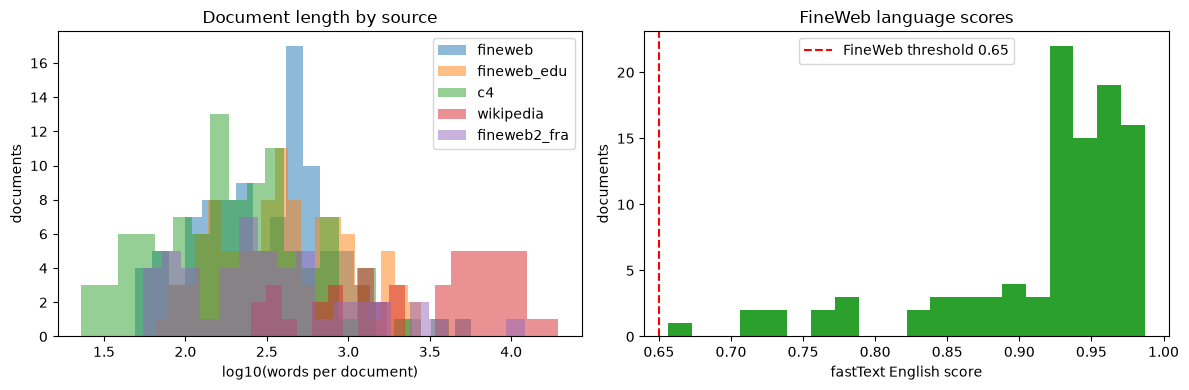

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, rows in samples.items():
    axes[0].hist(np.log10([max(1, r["full_words"]) for r in rows]), bins=20, alpha=0.5, label=name)
axes[0].set_xlabel("log10(words per document)"); axes[0].set_ylabel("documents"); axes[0].legend(); axes[0].set_title("Document length by source")
axes[1].hist(scores, bins=20, color="tab:green"); axes[1].axvline(0.65, color="r", ls="--", label="FineWeb threshold 0.65")
axes[1].set_xlabel("fastText English score"); axes[1].set_ylabel("documents"); axes[1].legend(); axes[1].set_title("FineWeb language scores")
plt.tight_layout(); plt.show()

(nb-acq-mixture)=
## 5. From a Compute Budget to a Mixture

Chapter 2 gives $C \approx 6ND$ and the Chinchilla optimum $D \approx 20N$. Chapter 3 adds the epoch constraint $w_s D / U_s \le 4$ per source. `plan_mixture` is the chapter's function; here it is run over a realistic source table, and then after the losses the consent study measured: about 5% of all web tokens and about 28% of the tokens from the best-maintained domains became off limits within a year.

In [8]:
def plan_mixture(total_tokens, sources, max_epochs=4.0):
    caps = {s: min(1.0, max_epochs * u / total_tokens) for s, (u, _) in sources.items()}
    if sum(caps.values()) < 1.0:
        raise ValueError("not enough unique data for this budget at this epoch cap")
    weights = {s: w for s, (_, w) in sources.items() if w > 0}
    if sum(caps[s] for s in weights) < 1.0:
        raise ValueError("the sources with a positive preferred weight cannot absorb the budget")
    total = sum(weights.values())
    weights = {s: w / total for s, w in weights.items()}
    clipped = set()
    while True:
        over = {s for s in weights if s not in clipped and weights[s] > caps[s] + 1e-12}
        if not over:
            break
        surplus = sum(weights[s] - caps[s] for s in over)
        for s in over:
            weights[s] = caps[s]
        clipped |= over
        free = {s: weights[s] for s in weights if s not in clipped}
        scale = sum(free.values())
        for s in free:
            weights[s] += surplus * free[s] / scale
    return {s: (weights.get(s, 0.0), weights.get(s, 0.0) * total_tokens, weights.get(s, 0.0) * total_tokens / sources[s][0]) for s in sources}


# Budget: an 8B model at 1e24 FLOPs, trained far past the Chinchilla point as production models are
C, N = 1e24, 8e9
D = C / (6 * N)
N_chin = math.sqrt(C / 120)
print(f"budget {C:.0e} FLOPs, N = {N/1e9:.0f}B  ->  D = {D/1e12:.1f}T tokens ({D/N:.0f} per parameter);"
      f" Chinchilla-optimal would be N* = {N_chin/1e9:.0f}B with D* = {20*N_chin/1e12:.1f}T")
assert abs(6 * N * D / C - 1) < 1e-9

sources = {                     # unique tokens after cleaning, preferred share
    "web":           (13.5e12,  0.70),   # the bulk of a filtered crawl
    "web_quality":   (1.5e12,   0.10),   # the best-maintained domains (news, reference, documentation)
    "code":          (1.0e12,   0.08),
    "papers":        (0.15e12,  0.04),
    "wikipedia":     (0.0045e12, 0.03),
    "books":         (0.03e12,  0.03),
    "dialogue":      (0.05e12,  0.02),
}
plan = plan_mixture(D, sources)
print(f"\n{'source':13}{'weight':>8}{'tokens':>10}{'epochs':>8}")
for s, (w, t, e) in plan.items():
    print(f"{s:13}{w:8.3f}{t/1e12:9.2f}T{e:8.2f}")
assert abs(sum(w for w, _, _ in plan.values()) - 1) < 1e-9
assert all(e <= 4 + 1e-9 for _, _, e in plan.values())
assert math.isclose(plan["wikipedia"][2], 4.0) and math.isclose(plan["books"][2], 4.0), "the small sources are pinned at the epoch cap"

budget 1e+24 FLOPs, N = 8B  ->  D = 20.8T tokens (2604 per parameter); Chinchilla-optimal would be N* = 91B with D* = 1.8T

source         weight    tokens  epochs
web             0.760    15.83T    1.17
web_quality     0.109     2.26T    1.51
code            0.087     1.81T    1.81
papers          0.029     0.60T    4.00
wikipedia       0.001     0.02T    4.00
books           0.006     0.12T    4.00
dialogue        0.010     0.20T    4.00


web           epochs 1.17 -> 1.23
web_quality   epochs 1.51 -> 2.09


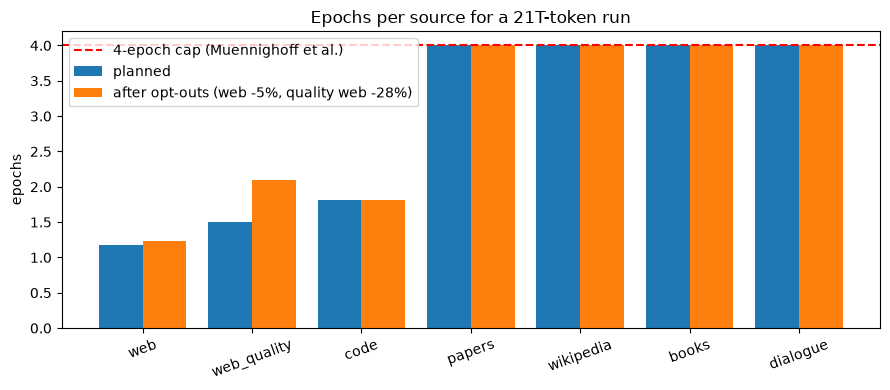

In [9]:
# Consent in Crisis (Longpre et al., 2024): within a year, robots.txt restrictions removed >5% of all
# C4 tokens and >28% of the tokens from the most actively maintained, highest-quality domains.
shrunk = dict(sources)
shrunk["web"] = (sources["web"][0] * 0.95, sources["web"][1])
shrunk["web_quality"] = (sources["web_quality"][0] * 0.72, sources["web_quality"][1])
plan_shrunk = plan_mixture(D, shrunk)
for s in ("web", "web_quality"):
    print(f"{s:13} epochs {plan[s][2]:.2f} -> {plan_shrunk[s][2]:.2f}")
assert plan_shrunk["web_quality"][2] > plan["web_quality"][2] and plan_shrunk["web"][2] > plan["web"][2]

fig, ax = plt.subplots(figsize=(9, 4))
names = list(sources)
ax.bar([i - 0.2 for i in range(len(names))], [plan[s][2] for s in names], 0.4, label="planned")
ax.bar([i + 0.2 for i in range(len(names))], [plan_shrunk[s][2] for s in names], 0.4, label="after opt-outs (web -5%, quality web -28%)")
ax.axhline(4, color="r", ls="--", label="4-epoch cap (Muennighoff et al.)")
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=20); ax.set_ylabel("epochs"); ax.legend()
ax.set_title(f"Epochs per source for a {D/1e12:.0f}T-token run")
plt.tight_layout(); plt.show()

(nb-acq-provenance)=
## 6. A Provenance Manifest

Every fetch above was recorded with its URL, size and SHA-256 of the bytes received. The manifest is what accompanies the raw data into Chapter 4. The committed samples carry checksums recorded when they were collected, and re-hashing them here is the reproducibility check.

In [10]:
def provenance_record(source, locator, sha256, nbytes, licence, robots_decision, live, synthetic=False):
    return {"source": source, "locator": locator, "sha256": sha256, "bytes": nbytes,
            "fetched_at": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()), "licence": licence,
            "robots": robots_decision, "live": live, "synthetic": synthetic}


LICENCES = {
    "data.commoncrawl.org": "Common Crawl terms of use",
    "en.wikipedia.org": "CC BY-SA 4.0",
    news_host: "site terms of service; robots.txt disallows AI crawlers",
    "datasets-server.huggingface.co": "per dataset: ODC-BY (FineWeb, FineWeb-Edu, FineWeb-2, C4), CC BY-SA (Wikipedia); sources' terms apply",
}
ROBOTS = {
    "en.wikipedia.org": f"article fetch allowed for *: {wiki['*'][0]}",
    news_host: f"CCBot allowed: {news['CCBot'][0]}; GPTBot allowed: {news['GPTBot'][0]}",
}
manifest = []
for f in FETCHED:
    host = urlparse(f["url"]).netloc
    manifest.append(provenance_record(host, f["url"], f["sha256"], f["bytes"], LICENCES.get(host, "unknown"),
                                      ROBOTS.get(host, "not applicable (data API, not a crawl)"), f["live"]))

# Reproducibility of the committed samples: every file hashes to what was recorded at collection time
mismatches = [name for name, digest in CHECKSUMS.items() if hashlib.sha256((DATA / name).read_bytes()).hexdigest() != digest]
assert not mismatches, f"committed samples changed since their checksums were recorded: {mismatches}"
assert all(len(m["sha256"]) == 64 for m in manifest)
assert len(manifest) >= 12, "manifest, 3 HEADs, WARC slice, two robots.txt files and five datasets"

live = sum(m["live"] for m in manifest)
print(f"{len(CHECKSUMS)} committed samples verified against checksums.json")
print(f"{len(manifest)} fetch records, {live} live, {len(manifest) - live} from committed samples\n")
for m in manifest:
    print(f"{m['sha256'][:12]}  {m['bytes']:>9,} B  {'live' if m['live'] else 'file'}  {m['locator'][:72]}")

10 committed samples verified against checksums.json
12 fetch records, 12 live, 0 from committed samples

3742ee3efd21    201,289 B  live  https://data.commoncrawl.org/crawl-data/CC-MAIN-2026-39/warc.paths.gz
b5e72ce4e693        645 B  live  https://data.commoncrawl.org/crawl-data/CC-MAIN-2026-39/segments/1788492
85dd6cdbf442        644 B  live  https://data.commoncrawl.org/crawl-data/CC-MAIN-2026-39/segments/1788492
a9617fe59f18        644 B  live  https://data.commoncrawl.org/crawl-data/CC-MAIN-2026-39/segments/1788492
94bb75fa4731    262,144 B  live  https://data.commoncrawl.org/crawl-data/CC-MAIN-2026-39/segments/1788492
48b98d80c844     28,275 B  live  https://en.wikipedia.org/robots.txt
04dee26f145e      8,547 B  live  https://www.nytimes.com/robots.txt
dd8e3594cfc2    334,240 B  live  https://datasets-server.huggingface.co/rows?dataset=HuggingFaceFW/finewe
a4eeea6d8ea2    419,904 B  live  https://datasets-server.huggingface.co/rows?dataset=HuggingFaceFW/finewe
0ad5a4995cac    22

## Summary

- A Common Crawl snapshot is about 100,000 WARC files of roughly a gigabyte each, about 90 TB in all; a byte-range request reads records from one without downloading it, and every fetched page yields request, response and metadata records.
- robots.txt is parsed by the standard library. Wikipedia opens articles to every agent and closes search pages to all of them; the news site allows Googlebot and disallows each AI crawler by name, which is the pattern the consent study measured spreading across the best-maintained sites.
- The hosted corpora differ in a hundred-document sample: Wikipedia articles are more than ten times longer than C4 pages, FineWeb documents are longer than C4's, FineWeb's language scores all clear its 0.65 threshold, and FineWeb-Edu's sample is entirely score 3 or above.
- An 8B model at $10^{24}$ FLOPs needs about 20T tokens; the small, high-quality sources hit the four-epoch cap first, and losing 5% of web text and 28% of its best slice to opt-outs pushes the remaining web sources toward the cap.
- Every fetch has a content hash and a licence note, and the committed samples verify against the checksums recorded when they were collected: the minimum that must travel with the data into Chapter 4.

For the reasoning behind each step, return to the [Data Acquisition and Sources chapter](../index.md).